# Clientes e previsão de receita

Duas perguntas da diretoria da Distribuidora Sul (dados fictícios), respondidas em Python sobre o mesmo banco dos painéis:

1. **Quais clientes mais importam e quais estão em risco?** Segmentação RFM: recência, frequência e valor.
2. **Quanto a empresa deve faturar em 2026?** Previsão mensal com sazonalidade e tendência, testada contra o que aconteceu em 2025.

Antes da análise, os números de partida são conferidos contra a view de conferência do painel Comercial.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "python"))
from carregar_sql import BANCO, conectar, escolher_driver

IMAGENS = RAIZ / "docs" / "img"
CORTE = pd.Timestamp("2025-12-31")   # data de corte de toda a base
conexao = conectar(r"localhost\SQLEXPRESS", BANCO, escolher_driver())


def ler(sql: str) -> pd.DataFrame:
    cursor = conexao.cursor().execute(sql)
    return pd.DataFrame([tuple(l) for l in cursor.fetchall()], columns=[c[0] for c in cursor.description])


# Os gráficos usam a mesma paleta dos painéis
AZUL, LARANJA, MARINHO, CINZA = "#2a78d6", "#F18F01", "#1F3B57", "#B4C1D0"
plt.rcParams.update({
    "font.family": "Segoe UI", "font.size": 11, "svg.fonttype": "path",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#C5D0DC",
    "axes.labelcolor": "#5B6775", "xtick.color": "#5B6775", "ytick.color": "#5B6775",
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlecolor": MARINHO, "axes.titlelocation": "left",
})
reais_mi = FuncFormatter(lambda v, _: f"R$ {v / 1e6:.1f} mi".replace(".", ","))
MESES = "jan fev mar abr mai jun jul ago set out nov dez".split()
mes_ano = lambda d: f"{MESES[d.month - 1]}/{d:%y}"
brl = lambda v: f"R$ {v:,.0f}".replace(",", ".")
pct = lambda v: f"{v:.1%}".replace(".", ",")

## 1. Dados e conferência

Uma linha por item de nota de venda (as devoluções ficam de fora, como no faturamento da DRE).

In [2]:
vendas = ler("""
    SELECT cal.data, v.cliente_key, c.razao_social AS cliente, c.tipo_cliente,
           CONCAT(v.filial_key, '-', v.nf_numero) AS nota,
           CAST(v.receita_liquida AS FLOAT) AS faturamento
    FROM dw.fato_venda v
    JOIN dw.dim_calendario cal ON cal.data_key = v.data_key
    JOIN dw.dim_cliente c      ON c.cliente_key = v.cliente_key
    WHERE v.tipo_operacao = 'VENDA'""")
vendas["data"] = pd.to_datetime(vendas["data"])
print(f"{len(vendas):,} itens de nota, {vendas.cliente_key.nunique()} clientes, de {vendas.data.min():%d/%m/%Y} a {vendas.data.max():%d/%m/%Y}")

93,206 itens de nota, 420 clientes, de 02/01/2024 a 31/12/2025


In [3]:
# O faturamento e os clientes de cada ano precisam bater com a view do painel Comercial
conferencia = ler("""SELECT ano, indicador, CAST(valor AS FLOAT) AS valor FROM dw.vw_conferencia_comercial
                     WHERE indicador IN (N'Faturamento', N'Clientes que Compraram')""")
calculado = vendas.groupby(vendas.data.dt.year).agg(
    **{"Faturamento": ("faturamento", "sum"), "Clientes que Compraram": ("cliente_key", "nunique")})
for _, linha in conferencia.iterrows():
    assert abs(calculado.loc[linha.ano, linha.indicador] - linha.valor) < 0.01, linha
print("Bate com dw.vw_conferencia_comercial")
calculado.rename_axis("ano").style.format({"Faturamento": brl})

Bate com dw.vw_conferencia_comercial


,Faturamento,Clientes que Compraram
ano,,
2024,R$ 58.906.528,386
2025,R$ 62.772.565,371


## 2. Segmentação RFM

Cada cliente recebe três notas de 1 a 5:

- **Recência (R):** dias desde a última compra em 31/12/2025. Como o cliente típico compra a cada 8 dias, as faixas são de negócio, e não quintis: até 15 dias = 5, até 30 = 4, até 60 = 3, até 90 = 2, mais de 90 = 1 (o mesmo corte de "parado" do painel Comercial).
- **Frequência (F)** e **valor (M):** notas e faturamento de 2025, em quintis entre os clientes que compraram no ano. Quem não comprou em 2025 fica com 1.

F e M viram uma nota só (a média, arredondada), e a combinação com R define o segmento.

In [4]:
clientes = vendas.groupby("cliente_key").agg(cliente=("cliente", "first"), tipo=("tipo_cliente", "first"),
                                             ultima_compra=("data", "max"))
v2025 = vendas[vendas.data.dt.year == 2025]
clientes["recencia"] = (CORTE - clientes.ultima_compra).dt.days
clientes["frequencia"] = v2025.groupby("cliente_key").nota.nunique()
clientes["valor"] = v2025.groupby("cliente_key").faturamento.sum()
clientes = clientes.fillna({"frequencia": 0, "valor": 0})

quintil = lambda s: pd.qcut(s.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
ativos = clientes.frequencia > 0
clientes["R"] = pd.cut(clientes.recencia, [-1, 15, 30, 60, 90, np.inf], labels=[5, 4, 3, 2, 1]).astype(int)
clientes["F"] = 1
clientes["M"] = 1
clientes.loc[ativos, "F"] = quintil(clientes.loc[ativos, "frequencia"])
clientes.loc[ativos, "M"] = quintil(clientes.loc[ativos, "valor"])
clientes["FM"] = np.floor((clientes.F + clientes.M) / 2 + 0.5).astype(int)


def segmento(c) -> str:
    if c.R >= 4 and c.FM >= 4:
        return "Campeões"
    if c.R >= 3 and c.FM >= 3:
        return "Fiéis"
    if c.R >= 4:
        return "Promissores"
    if c.R == 3:
        return "Precisam de atenção"
    if c.FM >= 3:
        return "Em risco"
    return "Hibernando" if c.frequencia > 0 else "Perdidos"


ORDEM = ["Campeões", "Fiéis", "Promissores", "Precisam de atenção", "Em risco", "Hibernando", "Perdidos"]
clientes["segmento"] = pd.Categorical(clientes.apply(segmento, axis=1), ORDEM, ordered=True)
segmentos = clientes.groupby("segmento", observed=False).agg(
    clientes=("valor", "size"), faturamento_2025=("valor", "sum"),
    dias_sem_comprar=("recencia", "median"), notas_2025=("frequencia", "median"))
segmentos["pct_clientes"] = segmentos.clientes / segmentos.clientes.sum()
segmentos["pct_faturamento"] = segmentos.faturamento_2025 / segmentos.faturamento_2025.sum()
segmentos.style.format({"faturamento_2025": brl, "pct_clientes": pct, "pct_faturamento": pct,
                        "dias_sem_comprar": "{:.0f}", "notas_2025": "{:.0f}"})

,clientes,faturamento_2025,dias_sem_comprar,notas_2025,pct_clientes,pct_faturamento
segmento,,,,,,
Campeões,148,R$ 51.590.857,2,45,"35,2%","82,2%"
Fiéis,89,R$ 5.403.588,7,26,"21,2%","8,6%"
Promissores,91,R$ 2.662.879,9,16,"21,7%","4,2%"
Precisam de atenção,7,R$ 172.651,42,17,"1,7%","0,3%"
Em risco,12,R$ 2.589.022,134,23,"2,9%","4,1%"
Hibernando,24,R$ 353.568,228,6,"5,7%","0,6%"
Perdidos,49,R$ 0,579,0,"11,7%","0,0%"


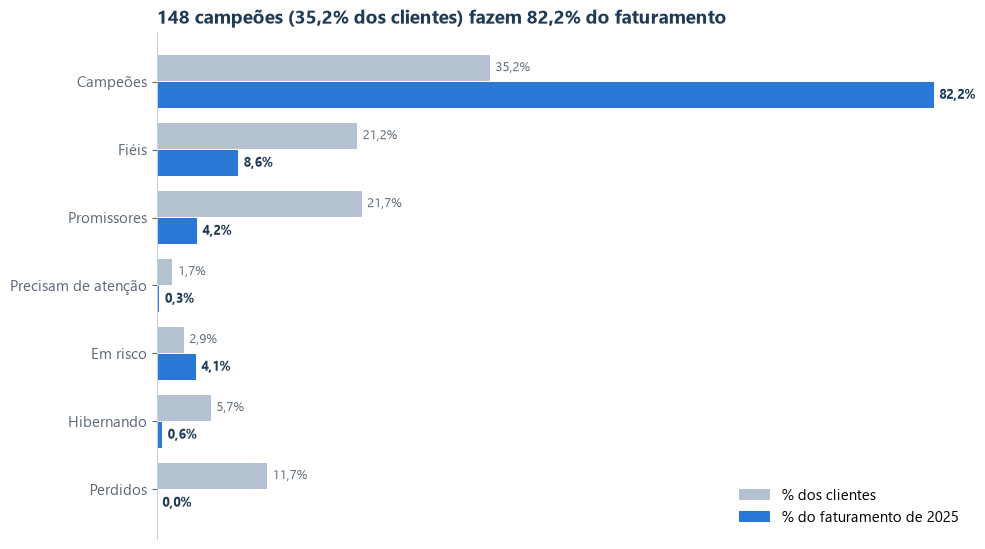

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.625))
y = np.arange(len(ORDEM))
ax.barh(y - 0.2, segmentos.pct_clientes, height=0.38, color=CINZA, label="% dos clientes")
ax.barh(y + 0.2, segmentos.pct_faturamento, height=0.38, color=AZUL, label="% do faturamento de 2025")
for i, (c, f) in enumerate(zip(segmentos.pct_clientes, segmentos.pct_faturamento)):
    ax.text(c + 0.006, i - 0.2, pct(c), va="center", fontsize=9, color="#5B6775")
    ax.text(f + 0.006, i + 0.2, pct(f), va="center", fontsize=9, color=MARINHO, fontweight="bold")
ax.set_yticks(y, ORDEM)
ax.invert_yaxis()
ax.xaxis.set_visible(False)
ax.spines[["bottom"]].set_visible(False)
campeoes = segmentos.loc["Campeões"]
ax.set_title(f"{int(campeoes.clientes)} campeões ({pct(campeoes.pct_clientes)} dos clientes) fazem {pct(campeoes.pct_faturamento)} do faturamento")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(IMAGENS / "analise_segmentos.svg")
plt.show()

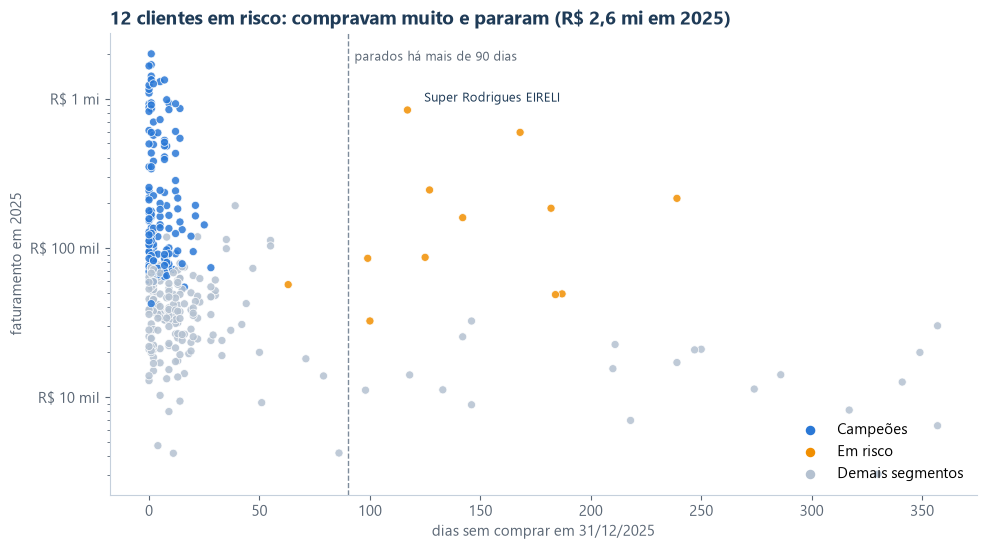

In [6]:
# Quem comprava muito e parou: valor de 2025 contra dias sem comprar, para quem comprou no ano
ano = clientes[ativos]
cores = ano.segmento.map({"Em risco": LARANJA, "Campeões": AZUL}).fillna(CINZA)
fig, ax = plt.subplots(figsize=(10, 5.625))
ax.scatter(ano.recencia, ano.valor, c=cores, s=34, alpha=0.85, edgecolors="white", linewidths=0.6)
ax.axvline(90, color="#7D8B9B", linestyle="--", linewidth=1)
ax.text(93, ano.valor.max() * 0.9, "parados há mais de 90 dias", color="#5B6775", fontsize=9)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"R$ {v / 1e6:.0f} mi" if v >= 1e6 else f"R$ {v / 1e3:.0f} mil"))
ax.set_xlabel("dias sem comprar em 31/12/2025")
ax.set_ylabel("faturamento em 2025")
maior = ano[ano.segmento == "Em risco"].sort_values("valor").iloc[-1]
ax.annotate(maior.cliente, (maior.recencia, maior.valor), xytext=(12, 6), textcoords="offset points", fontsize=9, color=MARINHO)
for cor, rotulo in ((AZUL, "Campeões"), (LARANJA, "Em risco"), (CINZA, "Demais segmentos")):
    ax.scatter([], [], c=cor, s=34, label=rotulo)
ax.legend(loc="lower right", frameon=False)
em_risco = segmentos.loc["Em risco"]
ax.set_title(f"{int(em_risco.clientes)} clientes em risco: compravam muito e pararam ({reais_mi(em_risco.faturamento_2025)} em 2025)")
fig.tight_layout()
fig.savefig(IMAGENS / "analise_em_risco.svg")
plt.show()

In [7]:
# A lista para a equipe comercial: os clientes em risco, do que mais comprou para o que menos comprou
(clientes[clientes.segmento == "Em risco"]
 .sort_values("valor", ascending=False)[["cliente", "tipo", "ultima_compra", "recencia", "frequencia", "valor"]]
 .style.format({"ultima_compra": "{:%d/%m/%Y}", "valor": brl, "frequencia": "{:.0f}"}))

,cliente,tipo,ultima_compra,recencia,frequencia,valor
cliente_key,,,,,,
163,Super Rodrigues EIRELI,Supermercado,05/09/2025,117,44,R$ 837.545
349,Supermercados Dalla Costa ME,Supermercado,16/07/2025,168,38,R$ 593.002
339,Supermercados Müller ME,Supermercado,26/08/2025,127,20,R$ 243.820
391,Super Moraes ME,Supermercado,06/05/2025,239,18,R$ 214.203
270,Supermercado Brum EIRELI,Supermercado,02/07/2025,182,15,R$ 183.866
385,Supermercados Gaúcho Ltda,Supermercado,11/08/2025,142,19,R$ 159.052
285,Padaria Kunz Ltda,Padaria,28/08/2025,125,31,R$ 86.184
125,Churrascaria São Jorge ME,Restaurante,23/09/2025,99,35,R$ 84.914
40,Confeitaria Bertoldi ME,Padaria,29/10/2025,63,33,R$ 56.580


In [8]:
# Os 32 clientes parados do relatório para a diretoria, por segmento
parados = clientes[(clientes.recencia > 90) & ativos]
parados.groupby("segmento", observed=True).agg(clientes=("valor", "size"), faturamento_2025=("valor", "sum")) \
       .style.format({"faturamento_2025": brl})

,clientes,faturamento_2025
segmento,,
Em risco,11,R$ 2.532.442
Hibernando,21,R$ 317.511


**O que a segmentação mostra**

- **148 campeões** (35% dos clientes) fazem **82% do faturamento** de 2025. São sobretudo mercados de bairro e supermercados.
- **12 clientes estão em risco**: compravam muito e estão, em mediana, há 134 dias sem comprar. Somaram **R\$ 2,6 mi em 2025**. O maior é o Super Rodrigues EIRELI, parado desde setembro.
- Dos **32 parados** do relatório para a diretoria, **11 estão em risco e concentram R\$ 2,53 mi** do que os 32 compraram em 2025; os outros 21 são pequenos (hibernando, R\$ 0,32 mi). A lista de ligações deve começar pelos 11.
- **Promissores** (91 clientes compraram há pouco, mas compram pouco) são onde há espaço para vender mais: hotéis, lanchonetes e padarias.

## 3. Previsão da receita de 2026

O método é simples de explicar à diretoria: **o faturamento de cada mês segue o mesmo formato dos anos anteriores (sazonalidade) e cresce na mesma taxa recente (tendência)**.

- Maio de 2024 foi atípico: as enchentes derrubaram as vendas da matriz em Porto Alegre. Ele fica fora do cálculo do crescimento e, na sazonalidade, é trocado pelo maio de 2025.
- Antes de prever 2026, o método é testado em 2025: com os dados até junho, ele prevê o segundo semestre, e a previsão é comparada com o real e com o orçamento.

In [9]:
mensal = vendas.set_index("data").faturamento.resample("MS").sum()
a24, a25 = mensal["2024"].to_numpy(), mensal["2025"].to_numpy()
sem_maio = np.arange(12) != 4
crescimento = a25[sem_maio].sum() / a24[sem_maio].sum() - 1
print(f"Crescimento de 2025 sobre 2024: {pct(a25.sum() / a24.sum() - 1)} com maio, {pct(crescimento)} sem maio")

Crescimento de 2025 sobre 2024: 6,6% com maio, 4,6% sem maio


In [10]:
orcado = ler("""
    SELECT cal.ano, cal.mes, CAST(SUM(o.valor) AS FLOAT) AS orcado
    FROM dw.fato_orcamento o
    JOIN dw.dim_conta c        ON c.conta_key = o.conta_key
    JOIN dw.dim_calendario cal ON cal.data_key = o.competencia_key
    WHERE c.cod_conta = '3.01' AND cal.ano = 2025
    GROUP BY cal.ano, cal.mes ORDER BY cal.mes""").orcado.to_numpy()

# Teste: com os dados até junho de 2025, o segundo semestre é o de 2024 crescido na taxa do primeiro semestre
cresc_semestre = a25[:6][sem_maio[:6]].sum() / a24[:6][sem_maio[:6]].sum() - 1
teste = pd.DataFrame({"real": a25[6:], "modelo": a24[6:] * (1 + cresc_semestre), "orçamento": orcado[6:]},
                     index=[mes_ano(d) for d in mensal["2025"].index[6:]])
erro_modelo = teste.modelo / teste.real - 1
erro_orcamento = teste["orçamento"] / teste.real - 1
print(f"Erro médio por mês:  modelo {pct(erro_modelo.abs().mean())}, orçamento {pct(erro_orcamento.abs().mean())}")
print(f"Erro no semestre:    modelo {pct(teste.modelo.sum() / teste.real.sum() - 1)}, "
      f"orçamento {pct(teste['orçamento'].sum() / teste.real.sum() - 1)}")
teste.style.format(brl)

Erro médio por mês:  modelo 5,8%, orçamento 2,1%
Erro no semestre:    modelo -0,1%, orçamento 2,2%


,real,modelo,orçamento
jul/25,R$ 5.809.911,R$ 5.878.224,R$ 5.858.700
ago/25,R$ 5.342.998,R$ 5.781.837,R$ 5.396.100
set/25,R$ 5.222.966,R$ 4.769.267,R$ 5.534.200
out/25,R$ 6.046.492,R$ 5.523.869,R$ 6.239.900
nov/25,R$ 4.754.026,R$ 4.902.549,R$ 4.759.900
dez/25,R$ 6.264.143,R$ 6.556.181,R$ 6.375.600


In [11]:
# Sazonalidade: o peso de cada mês no ano, média de 2024 (com o maio de 2025) e 2025
indice_24, indice_25 = a24 / a24.mean(), a25 / a25.mean()
indice_24[4] = indice_25[4]
sazonalidade = (indice_24 + indice_25) / 2
sazonalidade /= sazonalidade.mean()

total_2026 = a25.sum() * (1 + crescimento)
previsao = pd.Series(total_2026 / 12 * sazonalidade, index=pd.date_range("2026-01-01", periods=12, freq="MS"))
# Faixa do ano: o desvio dos erros mensais do teste, que em parte se compensam ao longo dos 12 meses
faixa = erro_modelo.std() / np.sqrt(12)
print(f"Previsão de 2026: R$ {total_2026 / 1e6:.1f} mi (+{pct(crescimento)}), "
      f"faixa de R$ {total_2026 * (1 - faixa) / 1e6:.1f} a {total_2026 * (1 + faixa) / 1e6:.1f} mi".replace(".", ","))
previsao.rename(index=mes_ano).to_frame("previsão").T.style.format(brl)

Previsão de 2026: R$ 65,7 mi (+4,6%), faixa de R$ 64,3 a 67,0 mi


,jan/26,fev/26,mar/26,abr/26,mai/26,jun/26,jul/26,ago/26,set/26,out/26,nov/26,dez/26
previsão,R$ 5.288.974,R$ 4.581.738,R$ 5.058.769,R$ 5.675.917,R$ 5.239.875,R$ 4.830.164,R$ 6.121.888,R$ 5.828.675,R$ 5.231.125,R$ 6.057.319,R$ 5.058.269,R$ 6.715.955


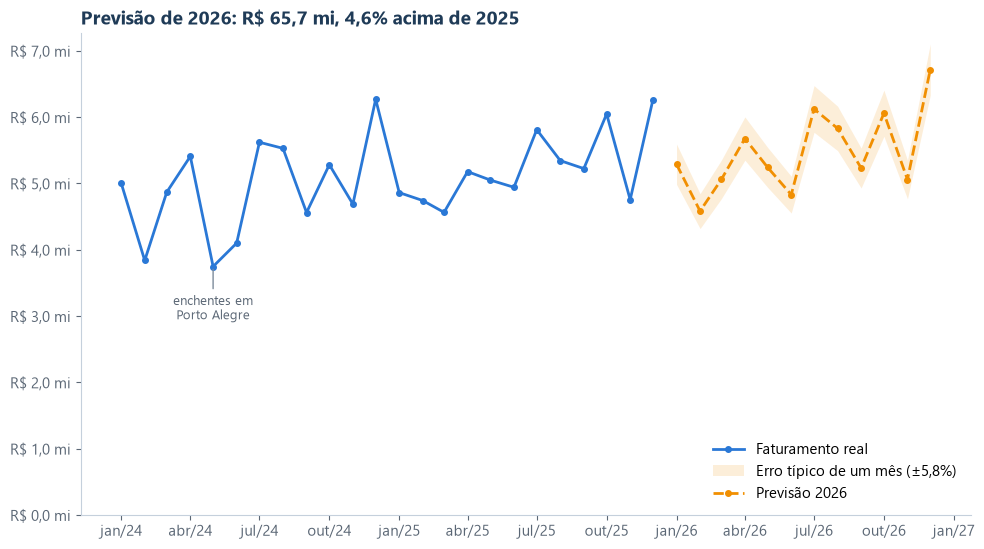

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.625))
ax.plot(mensal.index, mensal, color=AZUL, linewidth=2, marker="o", markersize=4, label="Faturamento real")
erro_mes = erro_modelo.abs().mean()
ax.fill_between(previsao.index, previsao * (1 - erro_mes), previsao * (1 + erro_mes), color=LARANJA, alpha=0.15,
                linewidth=0, label=f"Erro típico de um mês (±{pct(erro_mes)})")
ax.plot(previsao.index, previsao, color=LARANJA, linewidth=2, linestyle="--", marker="o", markersize=4, label="Previsão 2026")
ax.annotate("enchentes em\nPorto Alegre", (mensal.index[4], a24[4]), xytext=(0, -38), textcoords="offset points",
            ha="center", fontsize=9, color="#5B6775", arrowprops={"arrowstyle": "-", "color": "#7D8B9B"})
ax.yaxis.set_major_formatter(reais_mi)
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: mes_ano(mdates.num2date(v))))
ax.set_title(f"Previsão de 2026: R$ {total_2026 / 1e6:.1f} mi, {pct(crescimento)} acima de 2025".replace(".", ","))
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(IMAGENS / "analise_previsao.svg")
plt.show()

**O que a previsão mostra**

- No teste do segundo semestre de 2025, o método errou **0,1% no total** (o orçamento errou 2,2%), mas **5,8% em um mês típico** (o orçamento, 2,1%). O orçamento acerta melhor o formato de cada mês, porém fica sempre acima do real; o método acerta o nível. A sugestão é usar o método para a meta do ano e o formato mensal da controladoria para distribuí-la.
- A previsão para **2026 é R\$ 65,7 mi (+4,6%)**, numa faixa provável de **R\$ 64,3 mi a R\$ 67,0 mi**. Dezembro deve ser o maior mês (R\$ 6,7 mi) e fevereiro, o menor (R\$ 4,6 mi).
- Com o crescimento de maio incluído, a previsão subiria para quase R\$ 67 mi: o mesmo otimismo que deixou o orçamento de 2025 1,5% acima do realizado.

## Conclusões

1. A carteira depende de poucos clientes: 148 campeões fazem 82% das vendas. Acompanhar o segmento de cada cliente todo mês avisa antes que um campeão vire "em risco".
2. A recuperação de clientes deve começar pelos 11 em risco, que concentram quase 90% do que os 32 parados compravam.
3. Uma meta de R\$ 65,7 mi para 2026 é coerente com a tendência; acima de R\$ 67 mi, depende de recuperar clientes ou de ganhar novos.

In [13]:
conexao.close()